# What rounding the count target costs

Draws `fig:rounding-cost`. The computation is that of `three_channels_analysis/canal_1/canal1_rounding_cost.ipynb` (cells 3, 5, 7, 13), which is where the numbers are computed.

**The question.** `round()` is the ONLY step that manufactures zeros in the count target: `round(y·T/L) = 0` as soon as `L > 2yT`, so it is the most deeply sequenced spots that lose their small counts. `cp_nr` keeps the target continuous and is immune by construction. At identical model, seed, architecture, donors and genes, the gap `cp_nr − cp` IS the cost of the rounding, isolated.

**Two arms**, differing only in the common depth `T`:

| arm | run_id | TuPro | NSCLC | TLS |
|---|---|---|---|---|
| `median` | `pr_classic5_cp_vs_cp_nr_median` | 25 000 | 2 800 | 1 200 |
| `prod` | `pr_classic6_cp_vs_cp_nr` | 25 000 | 10 000 | 10 000 |

Three cohorts x two arms give a **dose-response**: the share of non-zero values destroyed runs from 1.6% to 57.5%.

Three things carry the argument, and the figure is drawn around them: the x axis is categorical (five measured conditions, not a continuum), the shaded band marks the depths actually used, and a filled marker means *no effect* where a hollow one means *effect not detected*.

In [7]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)

import src.evaluation.benchmark_summary as bs
importlib.reload(bs)          # so editing benchmark_summary.py does not need a kernel restart
from src.evaluation.benchmark_summary import (
    discover_run_summaries, headline_registry, paired_donor_deltas,
)

# The two arms. count_common_depth is the ONLY difference between them (same model types, same
# seed 42, same architecture, same preproc_id v5, same deferred chain, same corr selection).
RUNS = {
    "median": "pr_classic5_cp_vs_cp_nr_median",   # TuPro 25000 / NSCLC 2800 / TLS 1200
    "prod":   "pr_classic6_cp_vs_cp_nr",          # TuPro 25000 / NSCLC 10000 / TLS 10000
}
DATASETS = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS   = "r75"
METRIC   = "pearson"      # B = g*, the reported estimator. A is in the source notebook.

# The matched pairs. LEFT = rounded target, RIGHT = continuous target; nothing else differs between
# the two members (same class, same loss, same head, same seed).
# THE TWO RESTRICTED-DISPERSION NB HEADS ARE ABSENT: negativebinomial_spotdisp_cp and
# negativebinomial_genedisp_cp appear in no paper figure. They are removed HERE,
# so neither drawn nor printed: a head absent from the figure must not survive
# in the numbers.
PAIRS = [
    ("poisson_cp",                          "poisson_cp_nr"),
    ("negativebinomial_hetero_noanchor_cp", "negativebinomial_hetero_noanchor_cp_nr"),
]
MODELS = [m for pair in PAIRS for m in pair]

FIGDIR = PROJ / "results" / "_analysis" / "figures_paper"

# Fraction of NON-ZERO entries that round() sends to zero at each arm's T.
# These fractions are the x axis of the dose-response below.
ZERO_LOSS_PCT = {
    ("median", "10x_TuPro"): 1.6, ("median", "LUNG_CANCER"): 28.1, ("median", "TLS"): 57.5,
    ("prod",   "10x_TuPro"): 1.6, ("prod",   "LUNG_CANCER"):  2.5, ("prod",   "TLS"):  8.7,
}

# Both arms are loaded into ONE summaries list, with the arm prefixed onto the label. Two reasons:
# headline_registry restricts each (dataset, gene_set) block to the gene panel every summary
# SHARES, so loading them together makes the cross-arm comparison paired on genes too; and
# paired_donor_deltas can then pair any two labels, within OR across arms, from one frame.
summaries = []
for tag, run_id in RUNS.items():
    got = discover_run_summaries(PROJ / "results", run_id, DATASETS,
                                 radius=RADIUS, models=MODELS, lambda_keep=0.0)
    for s in got:
        s["label"] = f"{tag}::{s['label']}"
    summaries += got
    print(f"{tag:>6s}  {run_id:<32s}  {len(got):>2d} runs")

# A missing model means canal1 has not written its benchmark_summary.parquet yet. Warn loudly:
# every table below would silently shrink.
found   = {s["label"] for s in summaries}
missing = [f"{t}::{m}" for t in RUNS for m in MODELS if f"{t}::{m}" not in found]
print(f"\n{len(summaries)} runs loaded out of {len(RUNS) * len(MODELS) * len(DATASETS)} expected")
if missing:
    print(f"(!) missing (has canal1 run yet?): {missing}")

median  pr_classic5_cp_vs_cp_nr_median    12 runs
  prod  pr_classic6_cp_vs_cp_nr            8 runs

20 runs loaded out of 24 expected


## 1. The paired gap `cp_nr` − `cp`

The `_cp` model is the **reference** and its `_nr` twin the comparand, so `delta_mean > 0` means removing the rounding IMPROVES, i.e. the rounding was costing performance.

Pairing is done donor by donor. The donor effect dominates the raw spread (one model runs from ~0.13 to ~0.22 across donors on TuPro), so comparing two per-model intervals leaves that effect inside both and they overlap even when one model wins on nearly every donor. The per-donor difference cancels it exactly, and the interval on the difference is about ten times narrower.

Consequence for the wording: two overlapping intervals do NOT license "no difference". Only a bound on the MAGNITUDE of the gap does, and that is what this gives.

In [8]:
stats, donor_points = headline_registry(summaries, metrics=(METRIC,))

rows = []
for tag in RUNS:
    for cp, nr in PAIRS:
        d = paired_donor_deltas(donor_points, reference=f"{tag}::{cp}",
                                metric=METRIC, datasets=DATASETS)
        if d.empty:
            continue
        d = d[d["model"] == f"{tag}::{nr}"].copy()   # keep ONLY the twin, not the other models
        d["arm"], d["pair"] = tag, cp
        rows.append(d)
gap = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

if gap.empty:
    print("(!) no pairable pair -- both members of at least one pair are missing.")
else:
    print(f"{len(gap)} conditions (arm x cohort x pair) out of {len(RUNS) * len(PAIRS) * len(DATASETS)} expected")
    print(f"conditions whose donor CI excludes zero: {int(gap['excludes_zero'].sum())} / {len(gap)}")
    worst = gap.reindex(gap["delta_mean"].abs().sort_values(ascending=False).index).iloc[0]
    print(f"worst case over all conditions: {worst['delta_mean']:+.4f} Pearson "
          f"({worst['pair']}, {worst['dataset']}, arm {worst['arm']}), "
          f"IC [{worst['delta_ci_lo']:+.4f}, {worst['delta_ci_hi']:+.4f}]")

10 conditions (arm x cohort x pair) out of 12 expected
conditions whose donor CI excludes zero: 2 / 10
worst case over all conditions: +0.0180 Pearson (negativebinomial_hetero_noanchor_cp, LUNG_CANCER, arm median), IC [+0.0096, +0.0264]


## 2. The paper figure

Three properties of the source figure are kept because they carry the argument:

**Categorical x axis.** Five conditions were measured, not a continuum. A continuous axis would imply interpolation that was never run, and it would crush the three production conditions into the first tenth of the axis. The conditions are ordered by increasing destruction.

**The operating regime is shaded.** The left conditions are the depths actually used (TuPro 25 000, NSCLC 10 000, TLS 10 000). TuPro exists only in the `median` arm, but its `T` there IS its production value, so it belongs to the regime — which is why the set is listed explicitly rather than inferred from the arm name.

**Filled = detected.** Filled marker when the 95% interval excludes zero, hollow otherwise. That is what separates "no effect" from "effect not detected" without reading the numbers.

legend strip = 0.254 of the width
wrote -> fig_rounding_cost_paper.pdf  (+ .png)


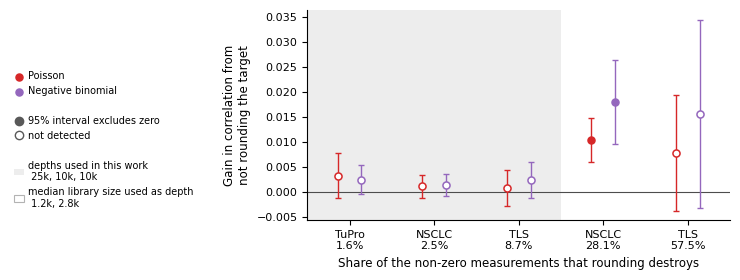


PRINTED TWIN - correlation gained by NOT rounding the target  ('*' = CI excluding zero)
  cohort   arm         lost  head                     delta                 95% CI     donors
  TuPro    median      1.6%  Negative binomial     +0.0025  [-0.0004, +0.0055]    6+/1   -
  TuPro    median      1.6%  Poisson               +0.0033  [-0.0011, +0.0078]    5+/2   -
  NSCLC    prod        2.5%  Negative binomial     +0.0014  [-0.0007, +0.0036]    5+/3   -
  NSCLC    prod        2.5%  Poisson               +0.0012  [-0.0011, +0.0035]    4+/4   -
  TLS      prod        8.7%  Negative binomial     +0.0025  [-0.0011, +0.0061]    4+/2   -
  TLS      prod        8.7%  Poisson               +0.0009  [-0.0027, +0.0045]    4+/2   -
  NSCLC    median     28.1%  Negative binomial     +0.0180* [+0.0096, +0.0264]    8+/0   -
  NSCLC    median     28.1%  Poisson               +0.0104* [+0.0061, +0.0147]    8+/0   -
  TLS      median     57.5%  Negative binomial     +0.0156  [-0.0032, +0.0344]    5+/1   

In [9]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FIGDIR.mkdir(parents=True, exist_ok=True)
STEM = "fig_rounding_cost_paper"

# CANONICAL model -> color map, keyed on model_type.
SERIES = [
    ("poisson_cp",                          "Poisson",            "#d62728"),   # red
    ("negativebinomial_hetero_noanchor_cp", "Negative binomial",  "#9467bd"),   # purple
]
DS_SHORT = {"10x_TuPro": "TuPro", "TLS": "TLS", "LUNG_CANCER": "NSCLC"}

# The depths actually used in this work: TuPro 25000 / NSCLC 10000 / TLS 10000. Listed explicitly
# rather than inferred from the arm name, because TuPro appears only in the "median" arm and its T
# THERE is already 25000, i.e. its production value -- inferring from the arm would misclassify it.
PROD_CONDS = {("median", "10x_TuPro"), ("prod", "LUNG_CANCER"), ("prod", "TLS")}

FIG_W         = 7.4    # width is the cheap axis: LaTeX places the figure at a fixed width
FIG_H         = 2.9
LEGEND_FS     = 7
LEGEND_GUTTER = 0.02

g = gap[gap["metric"] == METRIC].copy()
g["loss"] = [ZERO_LOSS_PCT[(a, d)] for a, d in zip(g["arm"], g["dataset"])]

# One x slot per MEASURED condition, ordered by destruction.
conds = g[["arm", "dataset", "loss"]].drop_duplicates().sort_values("loss").reset_index(drop=True)
xpos   = {(r["arm"], r["dataset"]): i for i, r in conds.iterrows()}
labels = [f"{DS_SHORT[r['dataset']]}\n{r['loss']:.1f}%" for _, r in conds.iterrows()]
k_prod = max(xpos[c] for c in PROD_CONDS if c in xpos)   # last slot of the operating regime

drawn = []      # the PRINTED TWIN: fed by what is ACTUALLY drawn
fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
ax.axvspan(-0.5, k_prod + 0.5, color="0.93", lw=0, zorder=0)
ax.axhline(0.0, color="0.3", lw=0.8, zorder=1)

off = np.linspace(-0.14, 0.14, len(SERIES))
for j, (pair, name, color) in enumerate(SERIES):
    s = g[g["pair"] == pair].copy()
    if s.empty:
        continue
    s["x"] = [xpos[(a, d)] + off[j] for a, d in zip(s["arm"], s["dataset"])]
    s = s.sort_values("x")
    ax.errorbar(s["x"], s["delta_mean"],
                yerr=[s["delta_mean"] - s["delta_ci_lo"], s["delta_ci_hi"] - s["delta_mean"]],
                fmt="none", ecolor=color, elinewidth=1.0, capsize=2.5, zorder=2)
    sig = s["excludes_zero"].to_numpy(dtype=bool)
    # The significant scatter carries the legend label and is called even when empty, so a series
    # with no significant point still appears in the legend with its color.
    ax.scatter(s["x"][sig], s["delta_mean"][sig], s=26, color=color, zorder=3, label=name)
    ax.scatter(s["x"][~sig], s["delta_mean"][~sig], s=26, facecolors="white",
               edgecolors=color, linewidths=1.1, zorder=3)
    for r in s.itertuples():
        drawn.append(dict(head=name, cohort=DS_SHORT[r.dataset], arm=r.arm, destroyed_pct=r.loss,
                          delta=r.delta_mean, lo=r.delta_ci_lo, hi=r.delta_ci_hi,
                          detected=bool(r.excludes_zero),
                          donors_better=int(r.n_donors_better), donors_worse=int(r.n_donors_worse)))

ax.set_xticks(range(len(conds)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_xlim(-0.5, len(conds) - 0.5)
ax.set_xlabel("Share of the non-zero measurements that rounding destroys", fontsize=8.5)
ax.set_ylabel("Gain in correlation from\nnot rounding the target", fontsize=8.5)
ax.tick_params(axis="y", labelsize=8)
# x in DATA coordinates, y as an axes fraction: insensitive to a ylim change, and center
# over the band so it reads as its legend.
# ax.text(k_prod / 2, 0.02, "depths used in this work", transform=ax.get_xaxis_transform(),
#         ha="center", va="bottom", fontsize=7.5, color="0.4")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

handles, _ = ax.get_legend_handles_labels()
spacer = Line2D([], [], ls="", marker="", label="")
spacer2 = Line2D([], [], ls="", marker="", label="")
# The BACKGROUND is an encoding in its own right: the shaded band
# is the operating regime, the white background the reduced depths of the median arm. The
# two patches carry the REAL colors of the plot, and the white one carries an edge, without
# which it would be invisible on a white legend.
handles += [spacer,
            Line2D([], [], marker="o", ls="", color="0.35", label="95% interval excludes zero"),
            Line2D([], [], marker="o", ls="", mfc="white", mec="0.35", label="not detected"),
            spacer2,
            Patch(facecolor="0.93", edgecolor="none", label="depths used in this work\n 25k, 10k, 10k"),
            Patch(facecolor="white", edgecolor="0.7", linewidth=0.8,
                  label="median library size used as depth\n 1.2k, 2.8k")]
leg = fig.legend(handles=handles, loc="center left", bbox_to_anchor=(0.0, 0.5),
                 ncol=1, frameon=False, fontsize=LEGEND_FS, handlelength=1.0,
                 handletextpad=0.5)
fig.canvas.draw()
legend_w = leg.get_window_extent().width / fig.bbox.width
fig.tight_layout(rect=(legend_w + LEGEND_GUTTER, 0, 1, 1))
print(f"legend strip = {legend_w:.3f} of the width")

for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"{STEM}.{ext}", dpi=300, bbox_inches="tight")
print(f"wrote -> {(FIGDIR / (STEM + '.pdf')).name}  (+ .png)")
plt.show()


# ======================== THE PRINTED TWIN OF THE FIGURE ======================================
# Exactly the drawn points and NOTHING else: the list comes from the drawing loop above,
# so a head absent from the figure is absent here too.
D = pd.DataFrame(drawn).sort_values(["destroyed_pct", "head"])
print("\n" + "=" * 108)
print("PRINTED TWIN - correlation gained by NOT rounding the target  ('*' = CI excluding zero)")
print("=" * 108)
print(f"  {'cohort':<8s} {'arm':<7s} {'lost':>8s}  {'head':<20s} {'delta':>9s} "
      f"{'95% CI':>22s} {'donors':>10s}")
for r in D.itertuples():
    star = "*" if r.detected else " "
    print(f"  {r.cohort:<8s} {r.arm:<7s} {r.destroyed_pct:>7.1f}%  {r.head:<20s} "
          f"{r.delta:>+8.4f}{star} [{r.lo:+.4f}, {r.hi:+.4f}] "
          f"{r.donors_better:>4d}+/{r.donors_worse:<4d}-")
print(f"\n  worst case among the DRAWN points: {D['delta'].abs().max():.4f} Pearson")
print(f"  points whose CI excludes zero: {int(D['detected'].sum())} / {len(D)}")
print(f"  in the operating regime (shaded band): "
      f"{int(D[D['destroyed_pct'] <= conds.loc[k_prod, 'loss']]['detected'].sum())} / "
      f"{len(D[D['destroyed_pct'] <= conds.loc[k_prod, 'loss']])}")